## Support Vector Machine

In [ ]:
import numpy as np
import pandas as pd

from sklearn import svm 
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score

from sklearn.model_selection import KFold,GridSearchCV

### Data Preparing

In [3]:
df = pd.read_csv('Covid Dataset.csv')
df1 = df.dropna()

In [4]:
for i in df1.columns:
    df1[i] = df1[i].apply(lambda x: 1 if x == 'Yes' else 0)
df1

,Breathing Problem,Fever,Dry Cough,Sore throat,Running Nose,Asthma,Chronic Lung Disease,Headache,Heart Disease,Diabetes,...,Fatigue,Gastrointestinal,Abroad travel,Contact with COVID Patient,Attended Large Gathering,Visited Public Exposed Places,Family working in Public Exposed Places,Wearing Masks,Sanitization from Market,COVID-19
0,1,1,1,1,1,0,0,0,0,1,...,1,1,0,1,0,1,1,0,0,1
1,1,1,1,1,0,1,1,1,0,0,...,1,0,0,0,1,1,0,0,0,1
2,1,1,1,1,1,1,1,1,0,1,...,1,1,1,0,0,0,0,0,0,1
3,1,1,1,0,0,1,0,0,1,1,...,0,0,1,0,1,1,0,0,0,1
4,1,1,1,1,1,0,1,1,1,1,...,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5429,1,1,0,1,1,1,1,0,0,0,...,1,1,0,0,0,0,0,0,0,1
5430,1,1,1,0,1,1,0,1,0,1,...,1,0,0,0,0,0,0,0,0,1
5431,1,1,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
5432,1,1,1,0,1,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
Y = df1['COVID-19']
X = df1.drop('COVID-19', axis=1)

### Modeling

In [5]:
model1 = svm.SVC(kernel='linear')

#### Evaluation Metrics

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for train_index, test_index in kf.split(X):
  
    X_train1, X_test1 = X.iloc[train_index], X.iloc[test_index]
    Y_train1, Y_test1 = Y.iloc[train_index], Y.iloc[test_index]
    
    model1.fit(X_train1, Y_train1)
    predictions = model1.predict(X_test1)
    
    acc = accuracy_score(Y_test1, predictions)
    precision = precision_score(Y_test1, predictions)
    recall = recall_score(Y_test1, predictions)
    f1 = f1_score(Y_test1, predictions)
    
    accuracy_scores.append(acc)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

print("Accuracy per fold:", accuracy_scores)
print("Precision per fold:", precision_scores)
print("Recall per fold:", recall_scores)
print("F1-Score per fold:", f1_scores)

print("\nAverage Accuracy:", np.mean(accuracy_scores))
print("Average Precision:", np.mean(precision_scores))
print("Average Recall:", np.mean(recall_scores))
print("Average F1-Score:", np.mean(f1_scores))

Accuracy per fold: [0.9733210671573137, 0.9558417663293468, 0.9760809567617296, 0.9724011039558418, 0.9594843462246777]
Precision per fold: [0.968236582694414, 0.9486338797814208, 0.9849710982658959, 0.9778516057585825, 0.9519650655021834]
Recall per fold: [1.0, 0.998849252013809, 0.9849710982658959, 0.9888017917133258, 1.0]
F1-Score per fold: [0.9838619922092376, 0.9730941704035875, 0.9849710982658959, 0.9832962138084632, 0.9753914988814317]

Average Accuracy: 0.9674258480857819
Average Precision: 0.9663316464004993
Average Recall: 0.9945244283986062
Average F1-Score: 0.9801229947137232


### Improving Model

In [ ]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    'C': np.arange(0.1, 10.1, 0.1),  # C controls the trade-off between smooth decision boundary and classifying training points correctly. Smaller values allow more margin violations.
    'gamma': [1, 0.1, 0.01],        # Gamma defines the influence of a single training example. A higher value leads to overfitting, while a smaller value increases generalization.
    'kernel': ['rbf', 'linear']     # Kernel specifies the type of decision boundary: 'rbf' for non-linear and 'linear' for a straight-line boundary.
}


kf = KFold(n_splits=5, shuffle=True, random_state=42)


grid = GridSearchCV(svm.SVC(), param_grid, cv=kf, verbose=2)

grid.fit(X_train1, Y_train1)


print('Optimal parameters:', grid.best_params_)


Fitting 5 folds for each of 600 candidates, totalling 3000 fits
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.7s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.6s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.8s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.6s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.8s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.0s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END ......................C=0.1, gamma=1, kernel=linear; total time=   0.1s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.3s
[CV] END .......................C=0.1, gamma=

In [ ]:
model2 = svm.SVC(kernel='rbf', gamma=0.1, C=5.6)

#### Evaluation Metrics

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for train_index, test_index in kf.split(X):
  
    X_train2, X_test2 = X.iloc[train_index], X.iloc[test_index]
    Y_train2, Y_test2 = Y.iloc[train_index], Y.iloc[test_index]
    
    model2.fit(X_train2, Y_train2)
    predictions = model2.predict(X_test2)
    
    acc = accuracy_score(Y_test2, predictions)
    precision = precision_score(Y_test2, predictions)
    recall = recall_score(Y_test2, predictions)
    f1 = f1_score(Y_test2, predictions)
    
    accuracy_scores.append(acc)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

print("Accuracy per fold:", accuracy_scores)
print("Precision per fold:", precision_scores)
print("Recall per fold:", recall_scores)
print("F1-Score per fold:", f1_scores)

print("\nAverage Accuracy:", np.mean(accuracy_scores))
print("Average Precision:", np.mean(precision_scores))
print("Average Recall:", np.mean(recall_scores))
print("Average F1-Score:", np.mean(f1_scores))

Accuracy per fold: [0.984360625574977, 0.9724011039558418, 0.9880404783808647, 0.9816007359705612, 0.9769797421731123]
Precision per fold: [0.9942987457240593, 0.9740112994350283, 0.994199535962877, 0.98989898989899, 0.9895953757225433]
Recall per fold: [0.9864253393665159, 0.9919447640966629, 0.9907514450867052, 0.9876819708846585, 0.981651376146789]
F1-Score per fold: [0.9903463940942646, 0.9828962371721779, 0.9924724956572091, 0.9887892376681614, 0.9856073690270581]

Average Accuracy: 0.9806765372110714
Average Precision: 0.9884007893486995
Average Recall: 0.9876909791162662
Average F1-Score: 0.9880223467237741


##### ROC curve

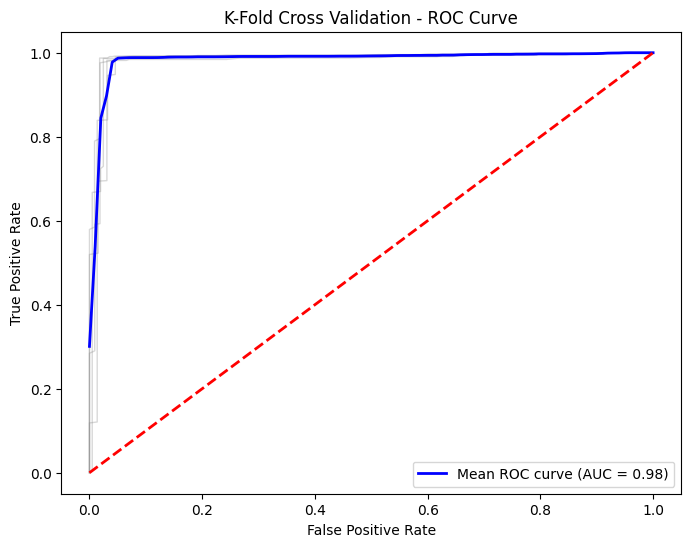

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc


X = df1.drop('COVID-19', axis=1).values
Y = df1['COVID-19'].values


kf = KFold(n_splits=5, shuffle=True, random_state=42)


model = SVC(kernel='rbf', gamma=1, C=0.8, probability=True)

fpr_all = []
tpr_all = []
roc_auc_all = []

for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = Y[train_index], Y[test_index]

    
    model.fit(X_train, y_train)

    
    y_score = model.predict_proba(X_test)[:, 1] 

  
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    fpr_all.append(fpr)
    tpr_all.append(tpr)
    roc_auc_all.append(roc_auc)


mean_fpr = np.linspace(0, 1, 100)
mean_tpr = np.mean([np.interp(mean_fpr, fpr, tpr) for fpr, tpr in zip(fpr_all, tpr_all)], axis=0)
mean_roc_auc = np.mean(roc_auc_all)


plt.figure(figsize=(8, 6))
for i in range(len(fpr_all)):
    plt.plot(fpr_all[i], tpr_all[i], lw=1, alpha=0.3, color='gray') 

plt.plot(mean_fpr, mean_tpr, color='b', label=f'Mean ROC curve (AUC = {mean_roc_auc:.2f})', lw=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='red', lw=2) 
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('K-Fold Cross Validation - ROC Curve')
plt.legend(loc='lower right')
plt.show()
